# Principal Component Analysis(PCA)

#### IMPORTING LIBRARIES

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

#### LOADING DATASET

In [32]:
df = pd.read_csv("Wine.csv")

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
df.head(5)

Number of samples: 178
Number of features: 14


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [33]:
df["Customer_Segment"].unique()

array([1, 2, 3])

#### DATA ANALYSIS

In [34]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64

No duplicate rows present.


#### SCALING

In [35]:
X = df.drop(columns=["Customer_Segment"])
y = df["Customer_Segment"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (142, 13)
Testing data shape: (36, 13)


In [37]:
model = KNeighborsClassifier()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Training Accuracy:{accuracy_score(y_train, y_train_pred):.2f}")
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy:0.98
Testing Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



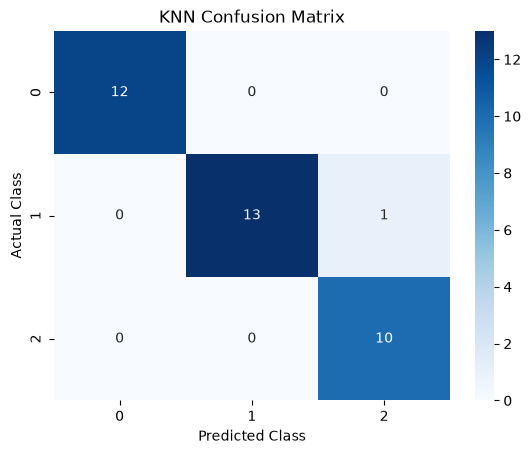

In [38]:
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")
plt.show()

## PRINCIPAL COMPONENT ANALYSIS

#### First decide how many principal components needed

In [39]:
# A principal component is a new feature created by combining your original features.
pca_full = PCA()
pca_full.fit(X_scaled)

pca_full.explained_variance_ratio_

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.02680749, 0.02222153, 0.01930019,
       0.01736836, 0.01298233, 0.00795215])

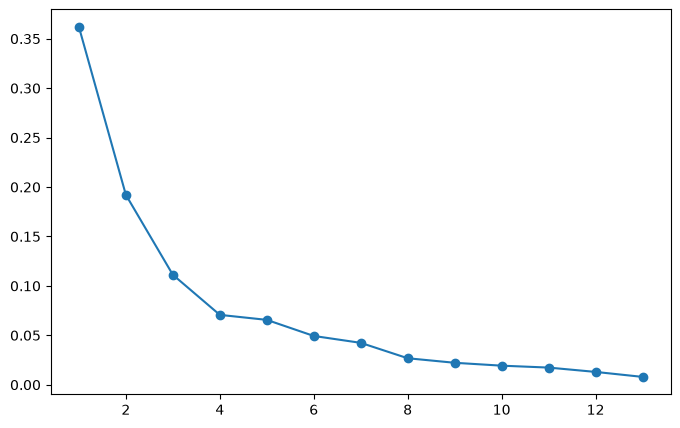

In [40]:
# It helps you understand how much information each component captures individually.
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker='o'
)

# there is a undrescroll at end - explained_variance_ratio_

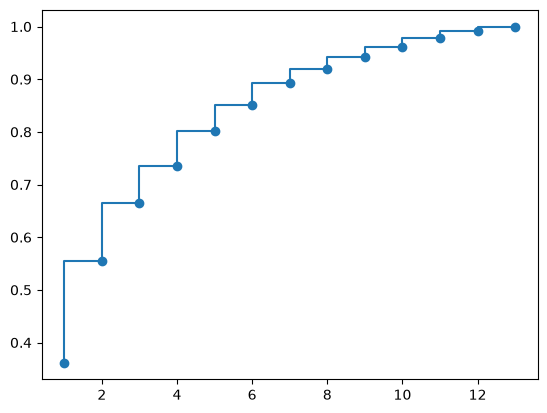

In [41]:
# This shows how much total variance you retain as you keep adding components.
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
)

In [46]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# here again do train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_pca, y,test_size=0.2,random_state=42,stratify=y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (142, 2)
Testing shape: (36, 2)


#### Visualization of reduced dimensions

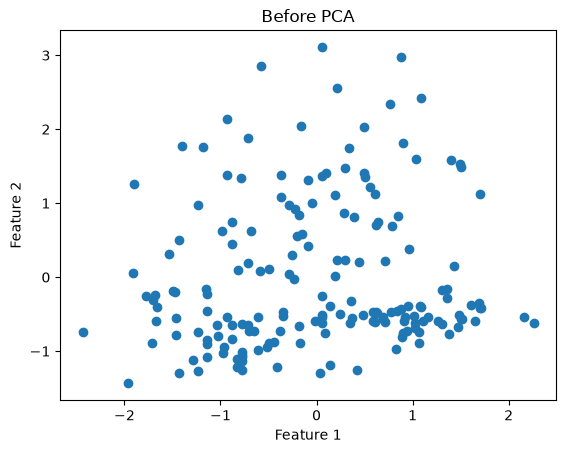

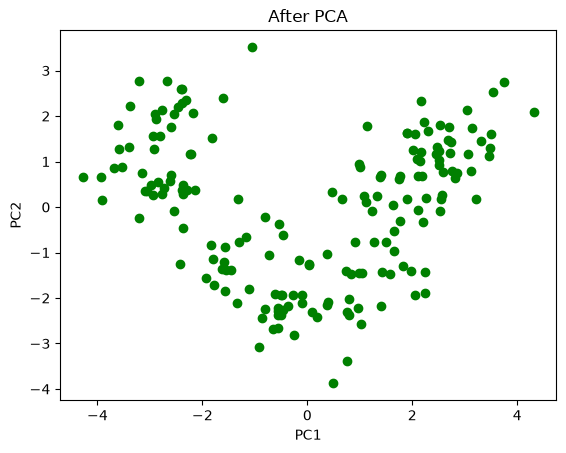

In [43]:
# before PCA
plt.scatter(X_scaled[:, 0], X_scaled[:, 1])
plt.title("Before PCA")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# after PCA
plt.scatter(X_pca[:, 0], X_pca[:, 1],color='green')
plt.title("After PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [44]:
# Variance Ratio
print(f"PCA1 {pca.explained_variance_ratio_[0]:.2f}")
print(f"PCA2 {pca.explained_variance_ratio_[1]:.2f}")

PCA1 0.36
PCA2 0.19


#### MATRICS AFTER PCA

In [45]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.9788732394366197
Testing Accuracy: 0.8888888888888888

Classification Report:
              precision    recall  f1-score   support

           1       0.92      0.92      0.92        12
           2       0.81      0.93      0.87        14
           3       1.00      0.80      0.89        10

    accuracy                           0.89        36
   macro avg       0.91      0.88      0.89        36
weighted avg       0.90      0.89      0.89        36

